# Multi-Domain Agricultural Exploratory Data Analysis (EDA)

This notebook conducts a multi-domain exploratory analysis across:
1. **PlantVillage Crop Disease Dataset:** Class imbalance, sample distributions, image dimensions, and embedding anomaly detection.
2. **NASA POWER Agroclimatology (2015–2024):** Monsoonal rainfall dynamics, temperature fluctuations, and humidity patterns across agricultural pilot zones in Nepal (Chitwan, Pokhara, Kathmandu).
3. **Tabular Regional Crop Yields & SoilGrids Profiles:** Historical harvest trajectories and agronomic physical/chemical soil constraints.

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 1. PlantVillage Class Imbalance Analysis

Total Processed Samples: 20632
Imbalance Ratio: 21.09x (Max: Tomato__Tomato_YellowLeaf__Curl_Virus vs Min: Potato___healthy)


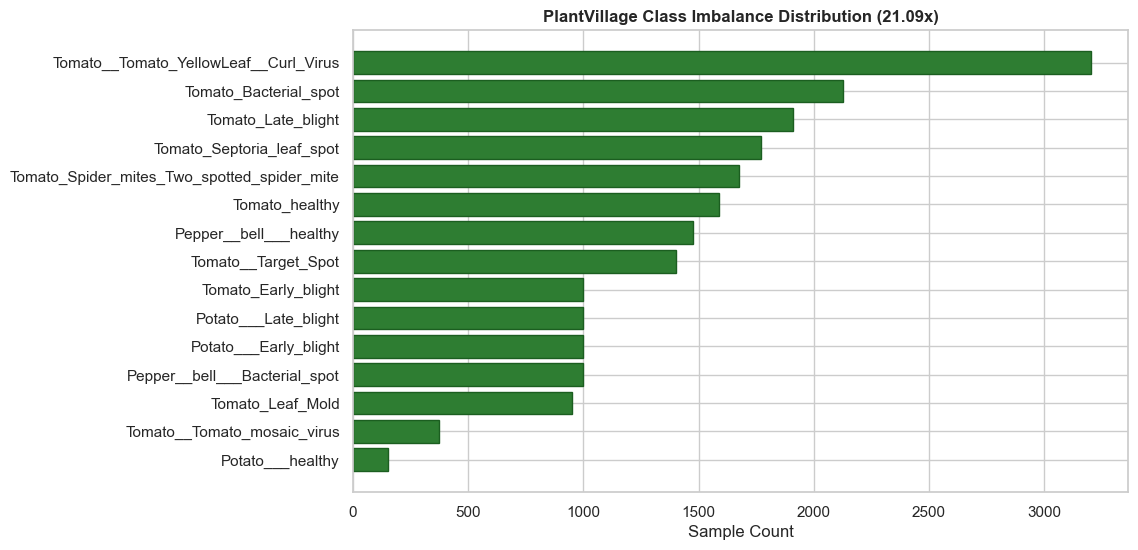

In [2]:
audit_path = Path("../reports/data_quality/plantvillage_audit.json")
if not audit_path.exists():
    audit_path = Path("reports/data_quality/plantvillage_audit.json")

with open(audit_path, "r", encoding="utf-8") as f:
    audit = json.load(f)

df_classes = pd.DataFrame([
    {
        "class_name": k,
        "raw_count": v["raw_count"],
        "processed_count": v["processed_count"],
        "flagged_outliers": v["flagged_outliers"],
        "outlier_pct": v["outlier_pct_of_raw"],
    }
    for k, v in audit["classes"].items()
]).sort_values("processed_count", ascending=True)

imbalance_ratio = df_classes["processed_count"].max() / df_classes["processed_count"].min()
print(f"Total Processed Samples: {df_classes['processed_count'].sum()}")
print(f"Imbalance Ratio: {imbalance_ratio:.2f}x (Max: {df_classes.iloc[-1]['class_name']} vs Min: {df_classes.iloc[0]['class_name']})")

plt.figure(figsize=(10, 6))
plt.barh(df_classes["class_name"], df_classes["processed_count"], color="#2E7D32", edgecolor="#1B5E20")
plt.title(f"PlantVillage Class Imbalance Distribution ({imbalance_ratio:.2f}x)", fontweight="bold")
plt.xlabel("Sample Count")
plt.show()

## 2. Suspicious Outliers & Feature Embedding Space

Total Records: 20638, Flagged Outliers: 256


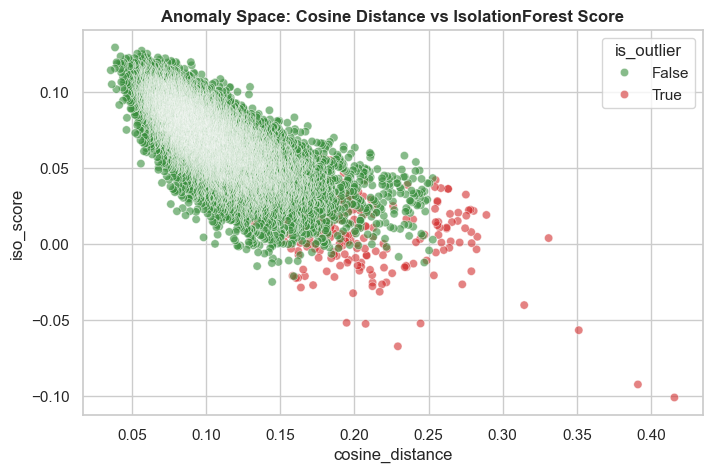

In [3]:
outlier_path = Path("../suspicious_outliers/outlier_report.csv")
if not outlier_path.exists():
    outlier_path = Path("suspicious_outliers/outlier_report.csv")

df_out = pd.read_csv(outlier_path)
print(f"Total Records: {len(df_out)}, Flagged Outliers: {(df_out['is_outlier'] == True).sum()}")

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_out,
    x="cosine_distance",
    y="iso_score",
    hue="is_outlier",
    palette={True: "#D32F2F", False: "#388E3C"},
    alpha=0.6,
)
plt.title("Anomaly Space: Cosine Distance vs IsolationForest Score", fontweight="bold")
plt.show()

## 3. NASA POWER Agroclimatology & Regional Seasonality

Total Weather Days Ingested: 10959 across regions: ['CHITWAN_TERAI' 'KATHMANDU_VALLEY' 'POKHARA_VALLEY']


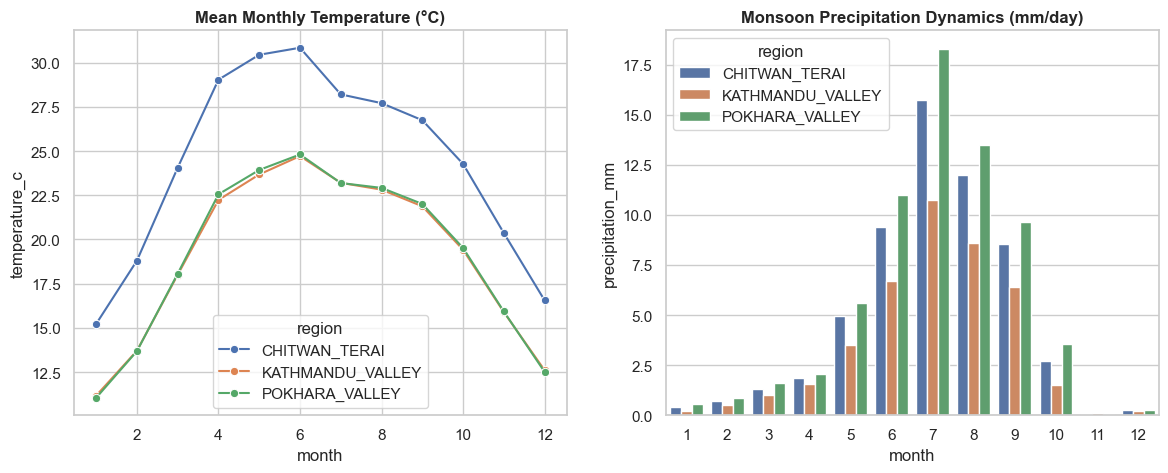

In [4]:
weather_dir = Path("../data/external/nasa_power")
if not weather_dir.exists():
    weather_dir = Path("data/external/nasa_power")

records = []
for f_path in weather_dir.glob("nasa_power_normalized_*.json"):
    with open(f_path, "r", encoding="utf-8") as f:
        records.extend(json.load(f))

df_w = pd.DataFrame(records)
df_w["record_date"] = pd.to_datetime(df_w["record_date"])
df_w["month"] = df_w["record_date"].dt.month
df_w["region"] = df_w["source_id"].apply(lambda s: s.replace("NASA_POWER_", ""))

print(f"Total Weather Days Ingested: {len(df_w)} across regions: {df_w['region'].unique()}")

monthly = df_w.groupby(["month", "region"]).agg({"temperature_c": "mean", "precipitation_mm": "mean"}).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=monthly, x="month", y="temperature_c", hue="region", marker="o", ax=ax[0])
ax[0].set_title("Mean Monthly Temperature (°C)", fontweight="bold")

sns.barplot(data=monthly, x="month", y="precipitation_mm", hue="region", ax=ax[1])
ax[1].set_title("Monsoon Precipitation Dynamics (mm/day)", fontweight="bold")
plt.show()

## 4. Tabular Crop Yield & Soil Profiles

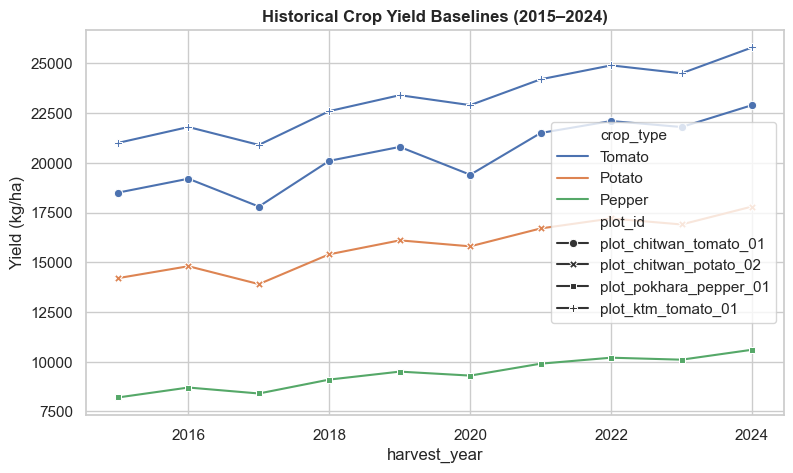

In [5]:
crop_path = Path("../data/external/tabular_crops/crop_yields.csv")
if not crop_path.exists():
    crop_path = Path("data/external/tabular_crops/crop_yields.csv")

df_yields = pd.read_csv(crop_path)
plt.figure(figsize=(9, 5))
sns.lineplot(data=df_yields, x="harvest_year", y="yield_kg_per_ha", hue="crop_type", style="plot_id", markers=True, dashes=False)
plt.title("Historical Crop Yield Baselines (2015–2024)", fontweight="bold")
plt.ylabel("Yield (kg/ha)")
plt.show()